In [1]:
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import DensityMatrix, entropy
import bosonic_qiskit as c2qa

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import DensityMatrix, entropy
import bosonic_qiskit as c2qa

# ---------------- fixed setup ----------------
N_SITES  = 8
CUTOFF   = 2
USE_MPS  = True
m        = int(np.ceil(np.log2(CUTOFF)))

wc = wa = 1.0
DETUNING = wc - wa
g  = 0.35

DT      = 0.05
T_MAX   = 60          
N_STEPS = int(T_MAX / DT)

INIT_SITE = N_SITES // 2
ENT_SITE  = INIT_SITE

J_VALUES = [0.02, 0.08, 0.20, 0.50]   

def qumode_qubits(site): return list(range(site*m, site*m+m))
def atom_qubit(site):    return N_SITES*m + site
def site_block(site):    return qumode_qubits(site) + [atom_qubit(site)]

N_MODE_OP = np.diag([min(k, CUTOFF-1) for k in range(2**m)]).astype(complex)
N_ATOM_OP = np.diag([1.0, 0.0]).astype(complex)
I_MODE, I_ATOM = np.eye(2**m), np.eye(2)
N_SITE_OP = np.kron(N_ATOM_OP, I_MODE) + np.kron(I_ATOM, N_MODE_OP)

def build_and_run(J):
    qmr = c2qa.QumodeRegister(num_qumodes=N_SITES, num_qubits_per_qumode=m)
    qr  = qiskit.QuantumRegister(N_SITES, name="atom")
    circuit = c2qa.CVCircuit(qmr, qr)

    for i in range(N_SITES):
        circuit.cv_initialize(1 if i == INIT_SITE else 0, qmr[i])
        circuit.x(qr[i])

    def trotter_step(circ):
        for i in range(N_SITES):
            circ.cv_jc(g * DT, 0.0, qmr[i], qr[i])
        if abs(DETUNING) > 1e-12:
            for i in range(N_SITES):
                circ.cv_r(wc * DT, qmr[i])
                circ.rz(wa * DT, qr[i])
        for i in range(N_SITES - 1):
            circ.cv_bs(-J * DT, qmr[i], qmr[i + 1])

    for site in range(N_SITES):
        circuit.save_density_matrix(qubits=site_block(site), label=f"s{site}_t0")
    for t in range(1, N_STEPS + 1):
        trotter_step(circuit)
        for site in range(N_SITES):
            circuit.save_density_matrix(qubits=site_block(site), label=f"s{site}_t{t}")

    backend = AerSimulator(method="matrix_product_state" if USE_MPS else "statevector")
    tcirc = transpile(circuit, backend)
    result = backend.run(tcirc).result()
    return result.data(0)



In [2]:
occ   = np.zeros((len(J_VALUES), N_STEPS + 1, N_SITES))
S_ent = np.zeros((len(J_VALUES), N_STEPS + 1))

[run] J = 0.02


c:\Users\LENOVO\OneDrive\Desktop\bosonic Qiskit\.venv\Lib\site-packages\scipy\sparse\linalg\_dsolve\linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
c:\Users\LENOVO\OneDrive\Desktop\bosonic Qiskit\.venv\Lib\site-packages\scipy\sparse\linalg\_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


[run] J = 0.08
[run] J = 0.2
[run] J = 0.5


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_23524\2375269761.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


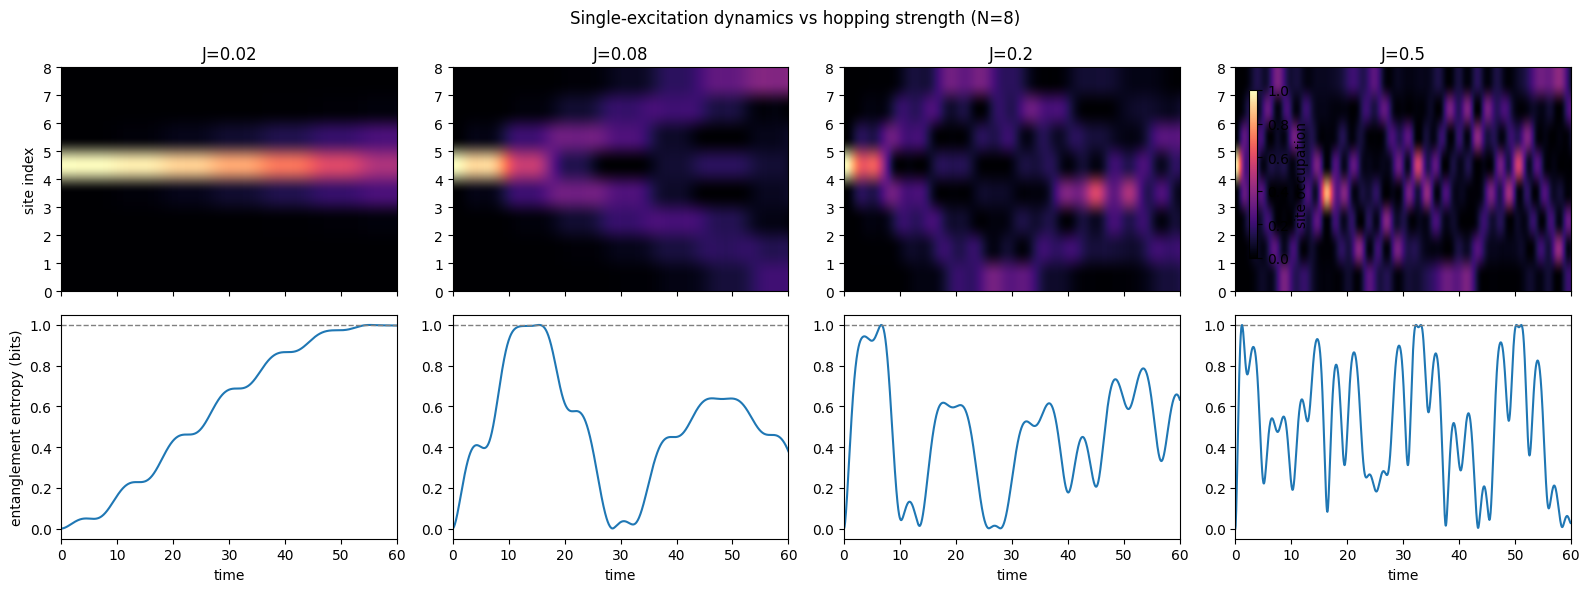

In [ ]:
# ---------------- run the sweep ----------------
occ   = np.zeros((len(J_VALUES), N_STEPS + 1, N_SITES))
S_ent = np.zeros((len(J_VALUES), N_STEPS + 1))

for k, J in enumerate(J_VALUES):
    print(f"[run] J = {J}")
    data = build_and_run(J)
    for t in range(N_STEPS + 1):
        for site in range(N_SITES):
            rho = data[f"s{site}_t{t}"]
            occ[k, t, site] = np.real(np.trace(rho @ N_SITE_OP))
        S_ent[k, t] = entropy(DensityMatrix(data[f"s{ENT_SITE}_t{t}"]), base=2)
    np.savez(f"jch_hopping_scan_J{J:.3f}.npz", occ=occ[k], S_ent=S_ent[k])

# ---------------- plot, same layout as your reference figure ----------------
time_axis = DT * np.arange(N_STEPS + 1)
fig, axes = plt.subplots(2, len(J_VALUES), figsize=(4 * len(J_VALUES), 6), sharex="col", constrained_layout=True)

for k, J in enumerate(J_VALUES):
    ax = axes[0, k]
    im = ax.imshow(occ[k].T, aspect="auto", origin="lower",
                    extent=[time_axis[0], time_axis[-1], 0, N_SITES],
                    cmap="magma", vmin=0, vmax=1)
    ax.set_title(f"J={J}")
    if k == 0:
        ax.set_ylabel("site index")

    axes[1, k].plot(time_axis, S_ent[k])
    axes[1, k].axhline(1.0, ls="--", color="gray", lw=1)
    axes[1, k].set_xlabel("time")
    if k == 0:
        axes[1, k].set_ylabel("entanglement entropy (bits)")

fig.suptitle(f"Single-excitation dynamics vs hopping strength (N={N_SITES})")
fig.colorbar(im, ax=axes[0, :].tolist(), location="right", shrink=0.8, pad=0.04, label="site occupation")
plt.show()

In [5]:
#save the data for later use
np.savez("jch_hopping_scan_data.npz", J_VALUES=J_VALUES, occ=occ, S_ent=S_ent, time_axis=time_axis)

In [3]:
#load the data for later use
data = np.load("jch_hopping_scan_data.npz")

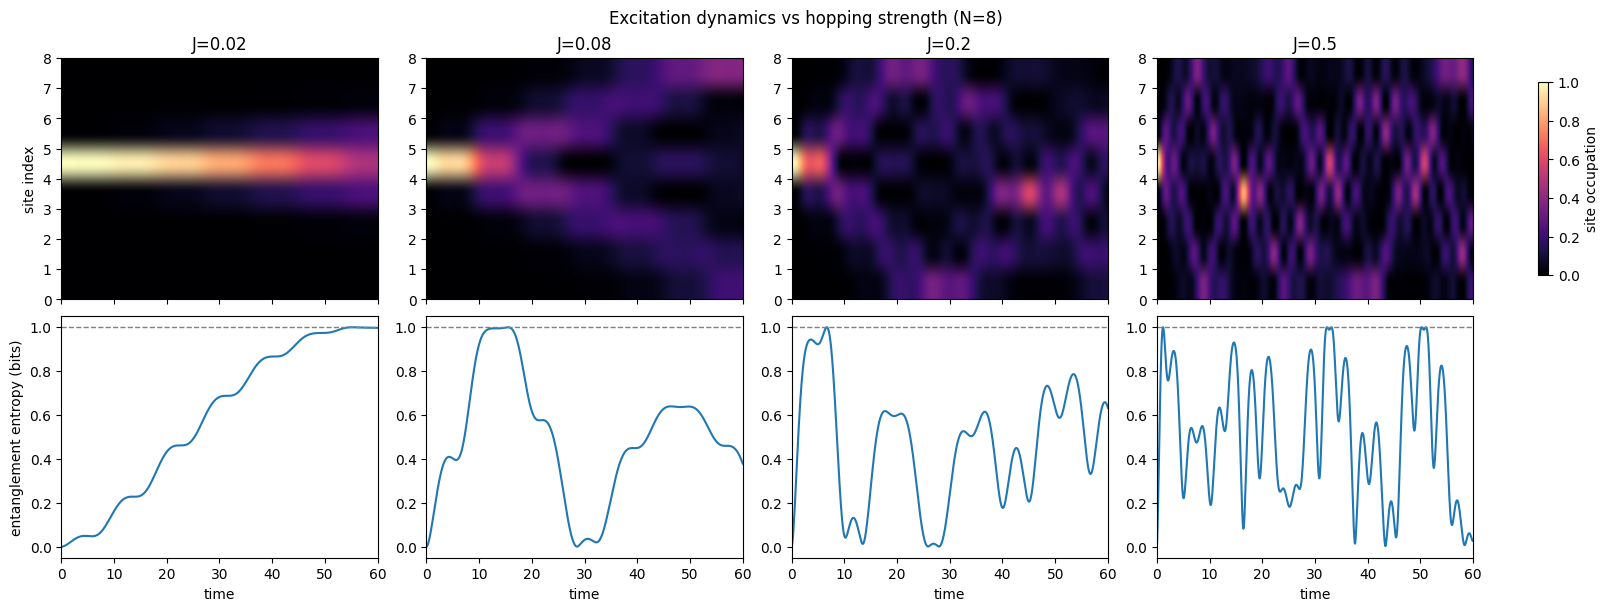

In [6]:
#plot the same graphs using the loaded data
occ = data['occ']
S_ent = data['S_ent']


time_axis = DT * np.arange(N_STEPS + 1)
fig, axes = plt.subplots(2, len(J_VALUES), figsize=(4 * len(J_VALUES), 6), sharex="col", constrained_layout=True)

for k, J in enumerate(J_VALUES):
    ax = axes[0, k]
    im = ax.imshow(occ[k].T, aspect="auto", origin="lower",
                    extent=[time_axis[0], time_axis[-1], 0, N_SITES],
                    cmap="magma", vmin=0, vmax=1)
    ax.set_title(f"J={J}")
    if k == 0:
        ax.set_ylabel("site index")

    axes[1, k].plot(time_axis, S_ent[k])
    axes[1, k].axhline(1.0, ls="--", color="gray", lw=1)
    axes[1, k].set_xlabel("time")
    if k == 0:
        axes[1, k].set_ylabel("entanglement entropy (bits)")

fig.suptitle(f"Excitation dynamics vs hopping strength (N={N_SITES})")
fig.colorbar(im, ax=axes[0, :].tolist(), location="right", shrink=0.8, pad=0.04, label="site occupation")
save_path = "excitation_dynamics_vs_hopping_strength.pdf"
plt.savefig(save_path, dpi=150)
plt.show()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_10796\2601869951.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1, k].legend(loc="lower right", fontsize=8, frameon=False)


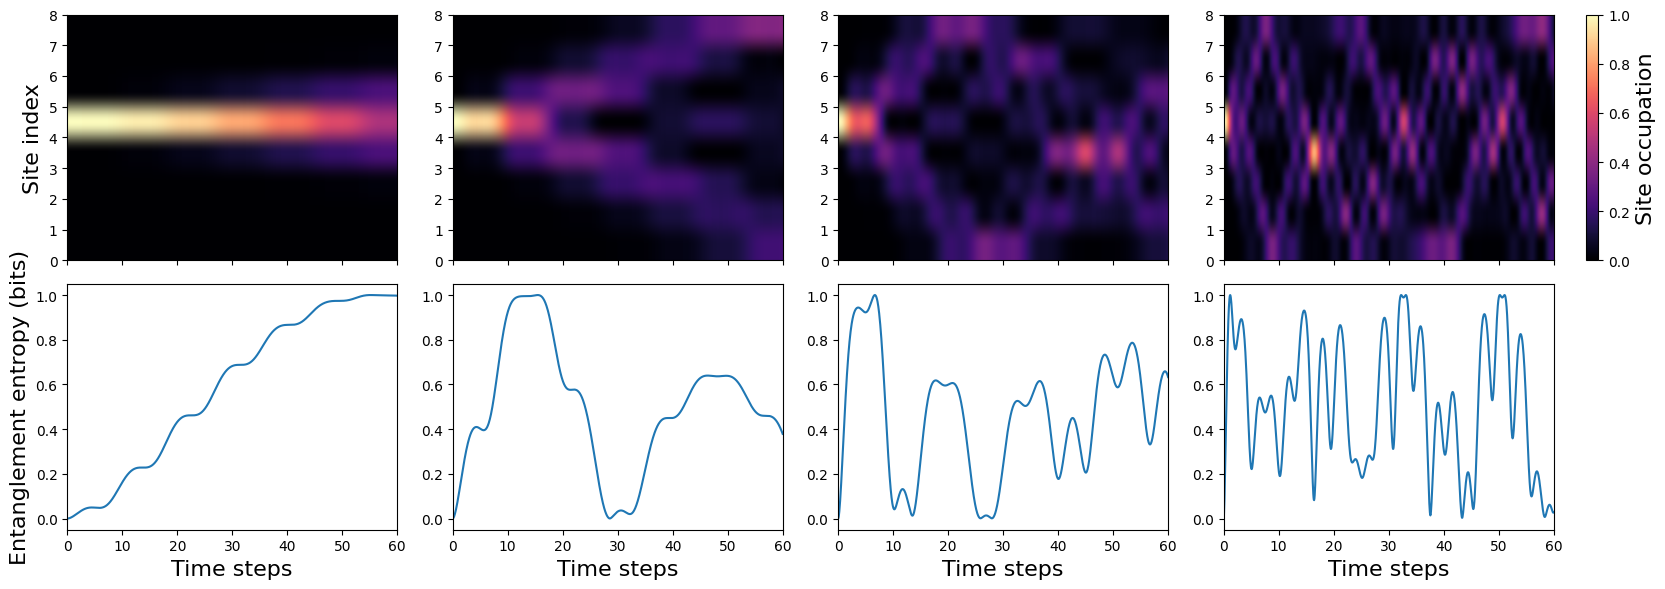

In [7]:
import numpy as np
import matplotlib.pyplot as plt

time_axis = DT * np.arange(N_STEPS + 1)
#S_MAX = np.log2(3)   # true ceiling within the single-excitation subspace (vacuum / photon / atom-excited)

fig, axes = plt.subplots(2, len(J_VALUES), figsize=(4 * len(J_VALUES) + 1.2, 6), sharex="col")

for k, J in enumerate(J_VALUES):
    ax = axes[0, k]
    im = ax.imshow(occ[k].T, aspect="auto", origin="lower",
                    extent=[time_axis[0], time_axis[-1], 0, N_SITES],
                    cmap="magma", vmin=0, vmax=1)
    #ax.set_title(f"J={J}")
    if k == 0:
        ax.set_ylabel("Site index", fontsize=16)

    axes[1, k].plot(time_axis, S_ent[k])
    #axes[1, k].axhline(S_MAX, ls="--", color="gray", lw=1,
                        #label=r"$\log_2 3$ (max)" if k == 0 else None) #this is the maximum entanglement entropy for a single-excitation subspace (vacuum, photon, atom-excited)
    axes[1, k].set_xlabel("Time steps", fontsize=16)
    #axes[1, k].set_ylim(0, 1.7)
    if k == 0:
        axes[1, k].set_ylabel("Entanglement entropy (bits)", fontsize=16)
        axes[1, k].legend(loc="lower right", fontsize=8, frameon=False)

#fig.suptitle(f"Excitation dynamics vs hopping strength (N={N_SITES})", fontsize=16)

#fix
plt.tight_layout(rect=[0, 0, 0.92, 1])
pos_top_right = axes[0, -1].get_position()
cax = fig.add_axes([pos_top_right.x1 + 0.015, pos_top_right.y0, 0.015, pos_top_right.height])
fig.colorbar(im, cax=cax, label="Site occupation")

#increase font size of colorbar label
cax.yaxis.label.set_fontsize(16)
#shrink the colorbar to make it more compact
cax.set_aspect(20)

plt.savefig("excitation_dynamics_vs_hopping_strength.pdf", dpi=150, bbox_inches="tight")
plt.show()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_10796\3435490704.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1, k].legend(loc="lower right", fontsize=8, frameon=False)


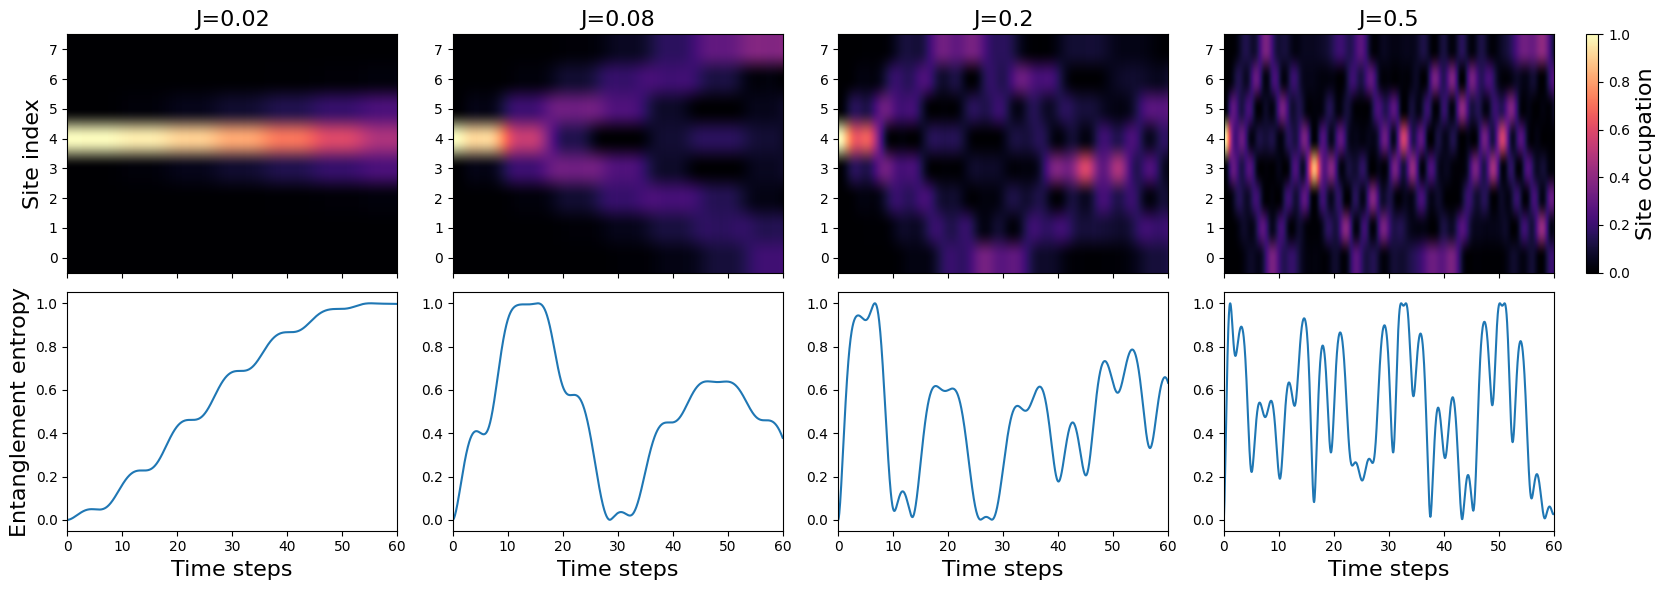

In [16]:
fig, axes = plt.subplots(2, len(J_VALUES), figsize=(4 * len(J_VALUES) + 1.2, 6), sharex="col")

for k, J in enumerate(J_VALUES):
    ax = axes[0, k]
    im = ax.imshow(occ[k].T, aspect="auto", origin="lower",
                    extent=[time_axis[0], time_axis[-1], -0.5, N_SITES - 0.5],  # <-- pixel-center fix
                    cmap="magma", vmin=0, vmax=1)
    ax.set_title(f"J={J}", fontsize=16)
    ax.set_yticks(range(N_SITES))          # force integer site labels 0..7
    if k == 0:
        ax.set_ylabel("Site index", fontsize=16)

    axes[1, k].plot(time_axis, S_ent[k])
    #axes[1, k].axhline(S_MAX, ls="--", color="gray", lw=1,
    #                    label=r"$\log_2 3$ (max)" if k == 0 else None)
    axes[1, k].set_xlabel("Time steps", fontsize=16)
    #axes[1, k].set_ylim(0, 1.7)
    if k == 0:
        axes[1, k].set_ylabel("Entanglement entropy", fontsize=16)
        axes[1, k].legend(loc="lower right", fontsize=8, frameon=False)

#fig.suptitle(f"Single-excitation dynamics vs hopping strength (N={N_SITES})", fontsize=16)

plt.tight_layout(rect=[0, 0, 0.92, 1])
pos_top_right = axes[0, -1].get_position()
cax = fig.add_axes([pos_top_right.x1 + 0.015, pos_top_right.y0, 0.015, pos_top_right.height])
fig.colorbar(im, cax=cax, label="Site occupation")

#increase font size of colorbar label
cax.yaxis.label.set_fontsize(16)
#shrink the colorbar to make it more compact
cax.set_aspect(20)

plt.savefig("excitation_dynamics_vs_hopping_strength.pdf", dpi=150, bbox_inches="tight")
plt.show()

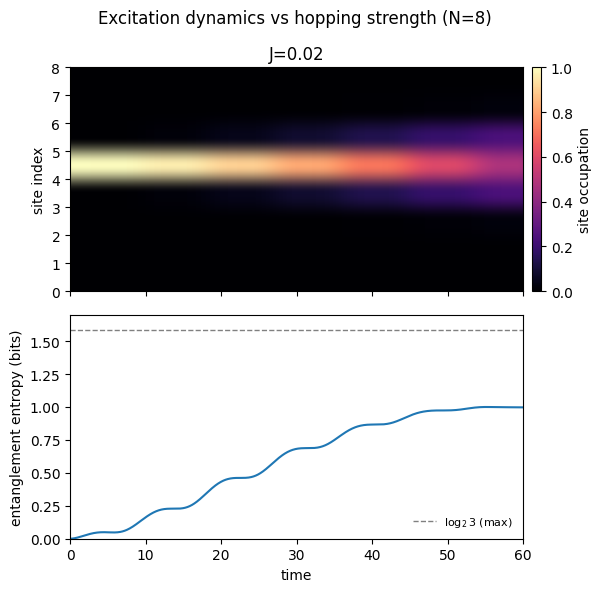

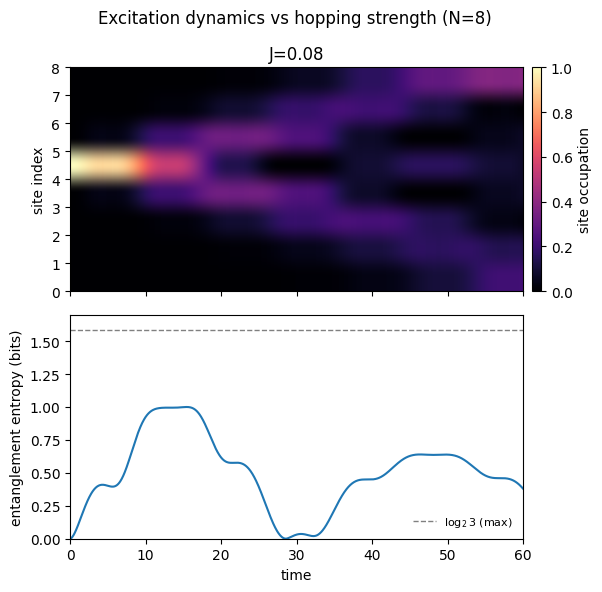

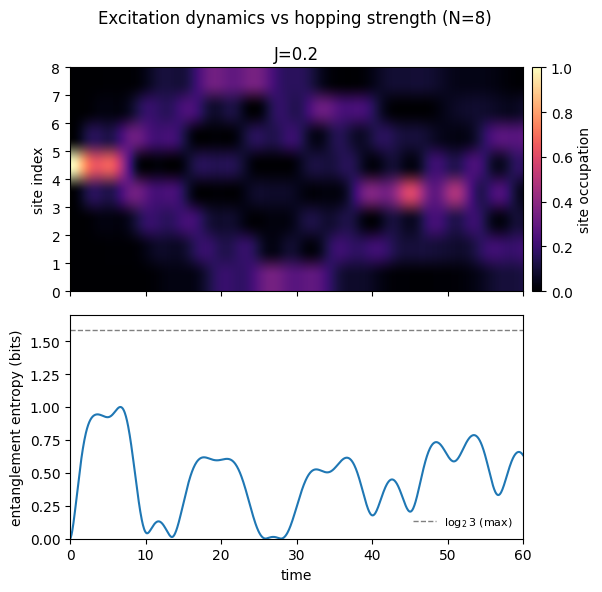

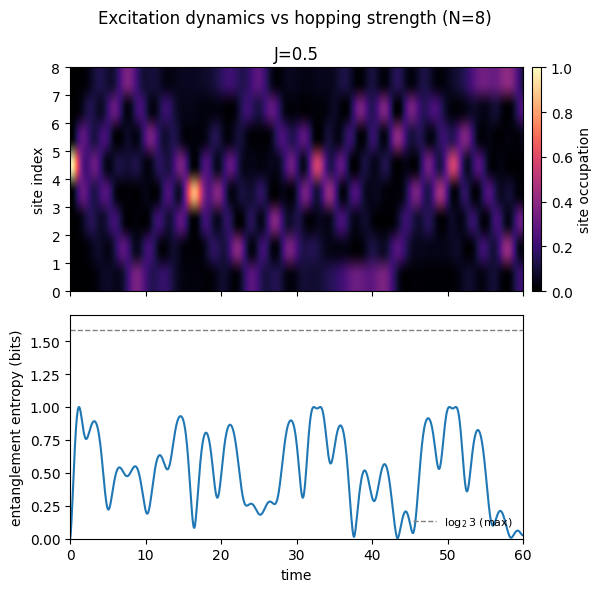

In [ ]:
#making 4 seperate plots for each J value
for k, J in enumerate(J_VALUES):
    fig, axes = plt.subplots(2, 1, figsize=(6, 6), sharex=True)

    ax = axes[0]
    im = ax.imshow(occ[k].T, aspect="auto", origin="lower",
                    extent=[time_axis[0], time_axis[-1], 0, N_SITES],
                    cmap="magma", vmin=0, vmax=1)
    ax.set_title(f"J={J}")
    ax.set_ylabel("site index")

    axes[1].plot(time_axis, S_ent[k])
    axes[1].axhline(S_MAX, ls="--", color="gray", lw=1,
                    label=r"$\log_2 3$ (max)")
    axes[1].set_xlabel("time")
    axes[1].set_ylim(0, 1.7)
    axes[1].set_ylabel("entanglement entropy (bits)")
    axes[1].legend(loc="lower right", fontsize=8, frameon=False)

    fig.suptitle(f"Excitation dynamics vs hopping strength (N={N_SITES})")

    # --- fix 1: dedicated colorbar axis, reserved margin so it never overlaps the last panel ---
    plt.tight_layout(rect=[0, 0, 0.92, 1])
    pos_top_right = axes[0].get_position()
    cax = fig.add_axes([pos_top_right.x1 + 0.015, pos_top_right.y0, 0.015, pos_top_right.height])
    fig.colorbar(im, cax=cax, label="site occupation")

    #plt.savefig(f"jch_hopping_scan_J{J:.3f}.pdf", dpi=150, bbox_inches="tight")
    plt.show()